In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [2]:
# Loading the Parkinson's dataset
data = pd.read_csv("parkinsons.data")
X = data.drop(columns=["name", "status"]).values

# NRMSE formula
def get_nrmse(true_data, imputed_data, mask):
    mse = np.mean((true_data[mask] - imputed_data[mask]) ** 2)
    var = np.var(true_data[mask])
    return np.sqrt(mse / var)

missing_rates = [0.10, 0.20, 0.30]
n_runs = 3  # averaged over 3 random runs chosen for processing speed

mean_nrmse = []
std_nrmse = []

for rate in missing_rates:
    run_scores = []
    for run in range(n_runs):
        # Generate MCAR mask
        np.random.seed(run * 10 + 42)
        mask = np.random.rand(*X.shape) < rate
        X_miss = X.copy()
        X_miss[mask] = np.nan
        
        imputer = IterativeImputer(
            estimator=RandomForestRegressor(
                n_estimators=50, 
                max_features="sqrt", 
                n_jobs=-1, 
                random_state=run
            ),
            max_iter=10,
            initial_strategy="mean",
            imputation_order="ascending",
            random_state=run
        )
        
        X_imputed = imputer.fit_transform(X_miss)
        run_scores.append(get_nrmse(X, X_imputed, mask))
        
    avg_score = np.mean(run_scores)
    sd_score = np.std(run_scores)
    mean_nrmse.append(avg_score)
    std_nrmse.append(sd_score)
    print(f"Missing {int(rate*100)}%: NRMSE = {avg_score:.4f} (SD {sd_score:.4f})")

# Values from Figure 1
rates_pct = [10, 20, 30]
paper_nrmse = [0.30, 0.31, 0.33]

C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Missing 10%: NRMSE = 0.2419 (SD 0.0783)


C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Missing 20%: NRMSE = 0.3070 (SD 0.0120)


C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Missing 30%: NRMSE = 0.3072 (SD 0.0336)


C:\Users\paulv\anaconda3\Lib\site-packages\sklearn\impute\_iterative.py:801: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


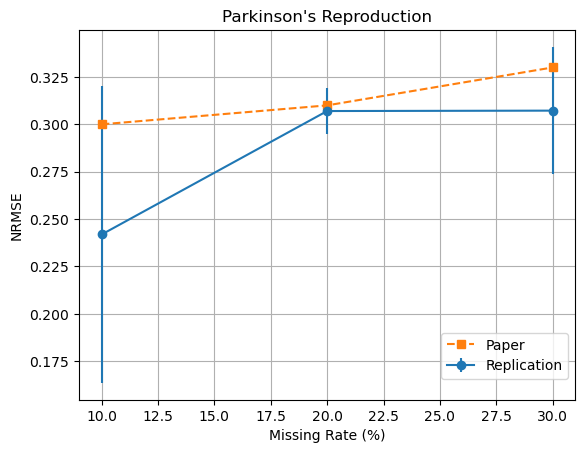

In [3]:
# Plot comparison
plt.errorbar(rates_pct, mean_nrmse, yerr=std_nrmse, marker='o', label='Replication')
plt.plot(rates_pct, paper_nrmse, marker='s', linestyle='--', label='Paper')
plt.grid(True)
plt.xlabel('Missing Rate (%)')
plt.ylabel('NRMSE')
plt.title("Parkinson's Reproduction")
plt.legend(bbox_to_anchor=(1,0.2))
plt.show()